# Assignment 5: Histogram Equalization and Histogram Matching

**Objective:**
1. Enhance contrast with histogram equalization (using the normalised CDF as a mapping).
2. Reshape an image's histogram to resemble a reference image (histogram matching / specification).

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part A: Histogram equalization
Compute the histogram, build the cumulative distribution (CDF), normalise it to 0-255 and use it as a lookup table.

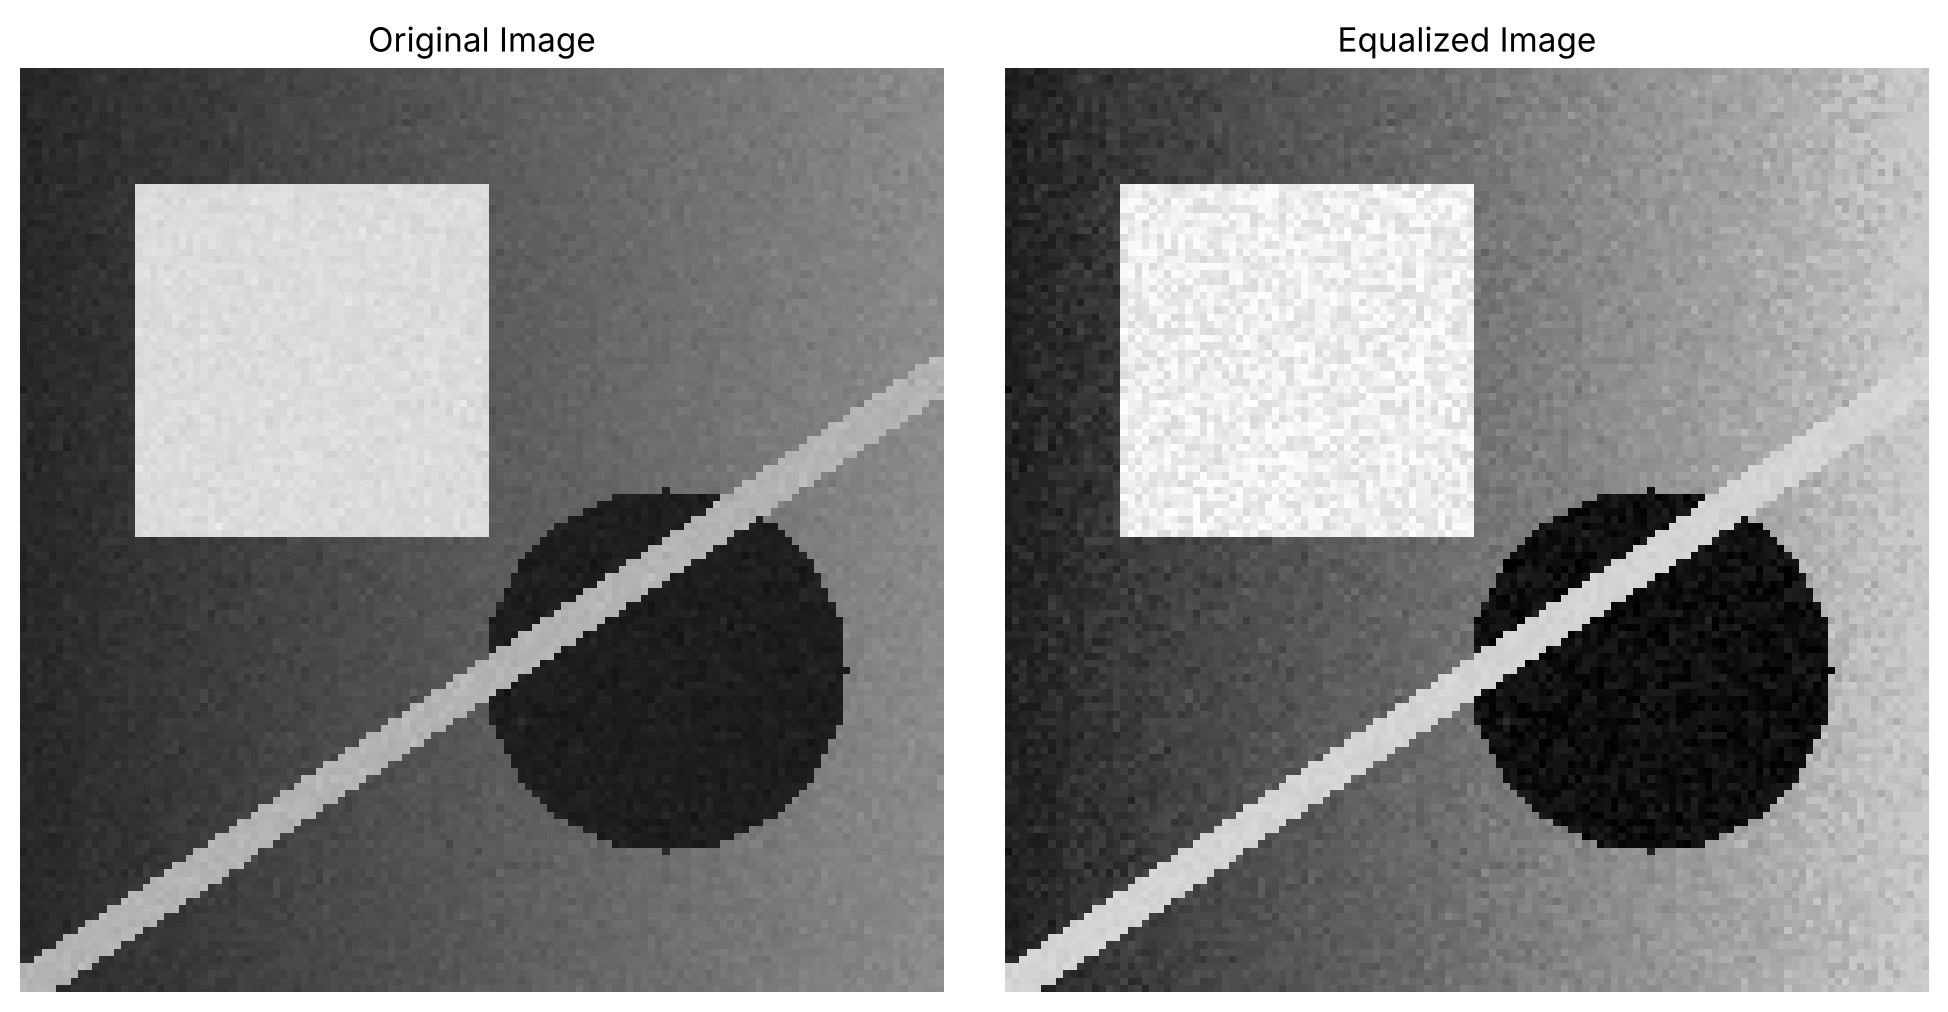

In [2]:
grayscale_image = create_demo_image()

histogram, _ = np.histogram(grayscale_image.flatten(), 256, [0, 256])
cumulative_distribution = histogram.cumsum()
cdf_normalized = (cumulative_distribution - cumulative_distribution.min()) * 255 / (cumulative_distribution.max() - cumulative_distribution.min())

equalized_image = np.interp(grayscale_image.flatten(), range(256), cdf_normalized).reshape(grayscale_image.shape).astype(np.uint8)

show_images([grayscale_image, equalized_image], ["Original Image", "Equalized Image"], figsize=(10, 5))

## Part B: Histogram matching
The reference image is a brightened, higher-contrast copy of the source (`1.5 x` source, clipped to 255). For every source intensity we pick the reference intensity whose CDF value is closest.

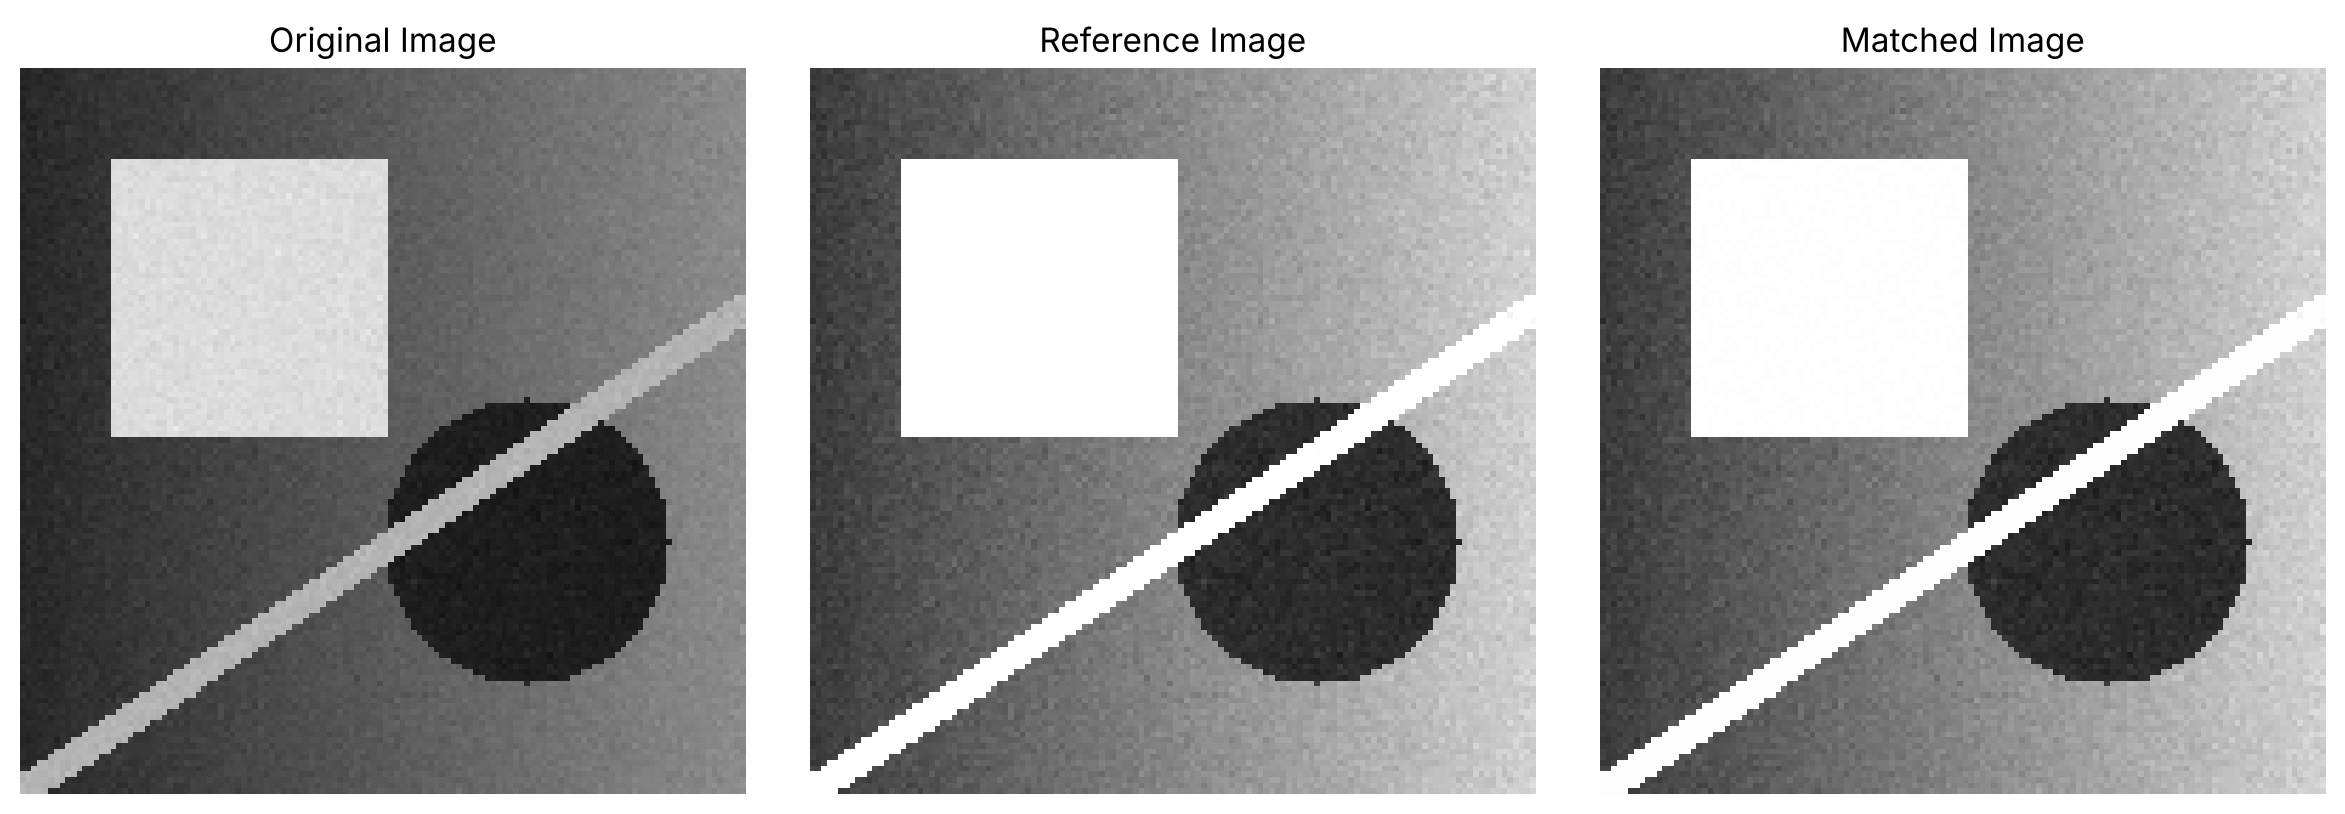

In [3]:
grayscale_image = create_demo_image()
reference_image = np.clip(grayscale_image * 1.5, 0, 255).astype(np.uint8)

source_histogram, _ = np.histogram(grayscale_image.flatten(), 256, [0, 256])
reference_histogram, _ = np.histogram(reference_image.flatten(), 256, [0, 256])

source_cdf = source_histogram.cumsum() / source_histogram.sum()
reference_cdf = reference_histogram.cumsum() / reference_histogram.sum()

lookup_table = np.zeros(256, dtype=np.uint8)
for level in range(256):
    lookup_table[level] = np.argmin(np.abs(source_cdf[level] - reference_cdf))

matched_image = lookup_table[grayscale_image]

show_images([grayscale_image, reference_image, matched_image],
            ["Original Image", "Reference Image", "Matched Image"], figsize=(12, 4))